# Alternative mass inputs and targets

Stellar mass is used as a substitute for log mass ratio. Stellar mass is a strong predictor of M200c, and stellar-mass estimates are available for the real Local Group.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'pyproject.toml').is_file())
def table(relative):
    return pd.read_csv(ROOT / 'results' / relative)
def saved_json(relative):
    return json.loads((ROOT / 'results' / relative).read_text(encoding='utf-8'))
plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 16)

The bound subhalo ratio is simulation-derived and needs an external halo-mass estimate
for the real system. We therefore compare dynamics alone with individual stellar masses,
their ratio, and their linear sum before taking the logarithm. The alternative target is
the sum of the two bound subhalo masses, in both host classes.

The point is to test whether the common-host versus summed-host M200c definition alone
explains the failure. Changing the target does not harmonize finder membership or input
stellar-mass definitions.


,run,target,mass_feature,population,subset,n,rmse,bias,r2,coverage68,coverage95,median_beta,rank_cdf_distance,mean_width68,mean_width95
0,bound_sum_dynamics,bound_subhalo_sum,none,transfer_tng,pooled,1530,0.355263,-0.185887,-0.179406,0.689542,0.863399,0.611708,0.270083,0.477291,0.937155
1,bound_sum_stellar_individual,bound_subhalo_sum,stellar_individual,transfer_tng,pooled,1530,0.378954,-0.356747,-0.341947,0.016340,0.252941,2.507039,0.853317,0.269797,0.527925
2,bound_sum_stellar_ratio,bound_subhalo_sum,stellar_ratio,transfer_tng,pooled,1530,0.319873,-0.191510,0.043871,0.654248,0.874510,0.693868,0.337388,0.451644,0.884425
3,bound_sum_stellar_sum,bound_subhalo_sum,stellar_sum,transfer_tng,pooled,1530,0.384295,-0.362768,-0.380044,0.016340,0.249673,2.502880,0.862397,0.272224,0.533544


,reference,candidate,population,subset,metric,n_pairs,n_components,estimate_delta,bootstrap_median_delta,ci95_low,ci95_high,fraction_below_zero,seed
0,bound_sum_dynamics,bound_sum_stellar_ratio,transfer_tng,pooled,rmse,1530,1521,-0.035391,-0.035336,-0.045246,-0.025182,1.0000,261950
1,bound_sum_dynamics,bound_sum_stellar_ratio,transfer_tng,pooled,bias,1530,1521,-0.005623,-0.005610,-0.011447,0.000580,0.9640,261950
2,bound_sum_dynamics,bound_sum_stellar_ratio,transfer_tng,pooled,abs_bias,1530,1521,0.005623,0.005610,-0.000580,0.011447,0.0360,261950
3,bound_sum_dynamics,bound_sum_stellar_ratio,transfer_tng,pooled,coverage68,1530,1521,-0.035294,-0.035329,-0.052392,-0.019620,1.0000,261950
4,bound_sum_dynamics,bound_sum_stellar_ratio,transfer_tng,pooled,coverage95,1530,1521,0.011111,0.011111,0.000653,0.022194,0.0190,261950
5,bound_sum_dynamics,bound_sum_stellar_ratio,transfer_tng,pooled,coverage_error68,1530,1521,0.016209,0.017396,-0.026694,0.043167,0.2305,261950
6,bound_sum_dynamics,bound_sum_stellar_ratio,transfer_tng,pooled,coverage_error95,1530,1521,-0.011111,-0.011111,-0.022194,-0.000653,0.9780,261950


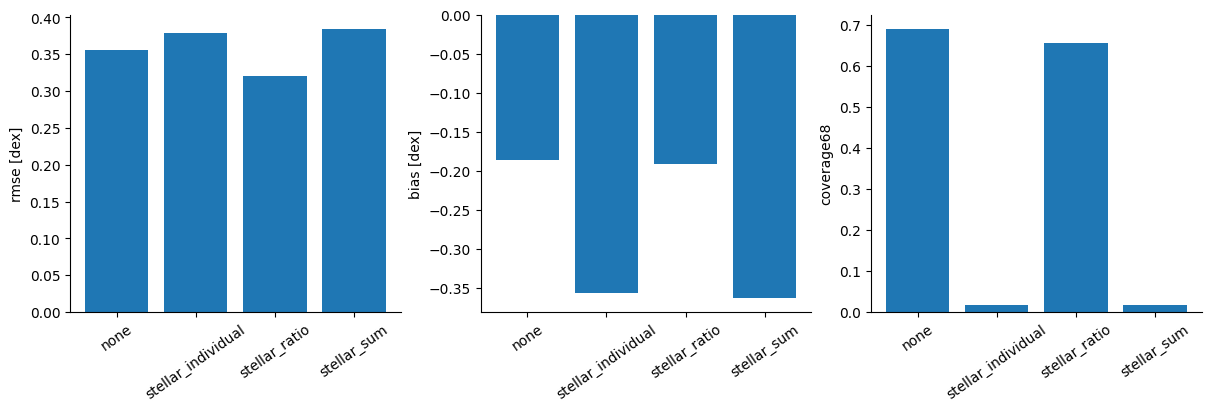

In [2]:
alternative=table('competing/alternative_target.csv')
display(alternative)
display(table('competing/alternative_target_paired_intervals.csv'))
fig,axes=plt.subplots(1,3,figsize=(12,4),layout='constrained')
for ax,metric in zip(axes,['rmse','bias','coverage68']):
    ax.bar(alternative.mass_feature,alternative[metric])
    ax.tick_params(axis='x',rotation=35);ax.set_ylabel(metric + (' [dex]' if metric!='coverage68' else ''))
plt.show()

Absolute stellar inputs still produce strong transfer bias under the alternate target.
The stellar ratio is more portable. Individual and summed stellar masses behave similarly,
suggesting sensitivity to the absolute normalization rather than merely how mass is divided.
These mass-representation comparisons use all 1530 TNG pairs. The normalization experiment
in the next notebook uses 231 held-out TNG pairs and separately fitted sum/individual models.

See the [feature definitions](../research/src/lg_npe/features.py),
[bound-mass export](../research/scripts/export_bound_subhalo_masses.py), and
[posterior evaluation](../research/notebooks/original/followup_posterior_evaluation.ipynb)
for the implementation.


[Previous](07_feature_diagnostics_and_ablation.ipynb) · [Next](09_stellar_normalization.ipynb) · [Repository map](../README.md)
